# Information-Free Novelty

Runs the scripts behind the figures so you can change things and see what happens.
The fitness landscape is loaded from `results/`, it took hours on Sheffield's Stanage
cluster to compute.

In [1]:
import os
import sys
import warnings
import numpy as np
from IPython.display import Image, Video, display

# run from the repo folder so scripts/ and results/ are found
while not os.path.isdir('scripts') and os.getcwd() != os.path.dirname(os.getcwd()):
    os.chdir('..')
sys.path.insert(0, os.getcwd())

from scripts import render_agent_single_patch, render_landscapes, render_mismatch_load
from scripts.compute_ladder import summarise
from scripts.fitness import evaluate_genome_per_world, eval_seeds
from scripts.params import BASE_PARAMS, ANCESTRAL_GENOME

warnings.filterwarnings('ignore')   # for the ODE which gives some warnings about the integration method

OUT = 'results/notebook'   # where the notebook saves its figures
os.makedirs(OUT, exist_ok=True)
STACK = 'results/ladder_res40/ladder_stack.npz'

## Single patch

The ancestral forager (R̄ = 8.7, κ = 2.98) starting in a corner away from a patch. Left
is where it goes, right is the membrane potential V and the opportunity cost β. `m` is
the mismatch, 0 is ancestral and 1 is modern.

saved results/notebook/single_patch.png  (harvested=15.3, n_steps=6179)


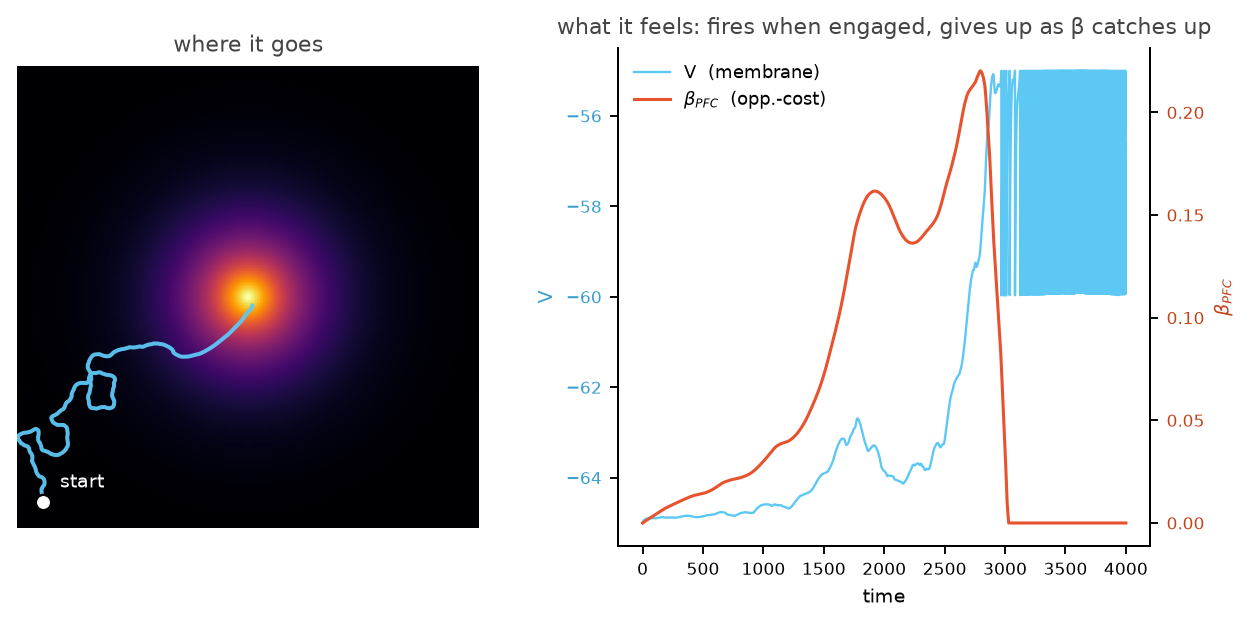

In [2]:
m = 0.10
render_agent_single_patch.render(f'{OUT}/single_patch.png', mismatch_index=m)
display(Image(f'{OUT}/single_patch.png'))

## Video

The same forager in a world with three patches, 8 seconds long.
`python -m scripts.render_forager_video` makes the full 40 second version.

In [3]:
from scripts import render_forager_video   # needs imageio-ffmpeg

m = 0.0
seed = 5   # a run where it gets through a few patches, change it for a different world
render_forager_video.render(f'{OUT}/forager.mp4', seed=seed, mismatch_index=m, seconds=8, fps=24)
display(Video(f'{OUT}/forager.mp4', embed=True, width=320))

  frame 0/192
  frame 150/192
saved results/notebook/forager.mp4  (harvested=20.5, patches left=1)


## Fitness landscape

Each square is a forager with a different R̄ (how rich it expects the world to be) and
κ (how much it likes novelty), averaged over 8 worlds. The axes are log scaled since
both traits span orders of magnitude, `even = True` plots them on normal axes.
`levels` can be any of 0, 0.05, 0.1, 0.2, 0.3, 0.5, 0.75 and 1.

shown rungs: ['0.00', '0.10', '0.30', '0.50', '1.00']  vmin=-0.103 vmax=0.714
saved results/notebook/landscapes.png


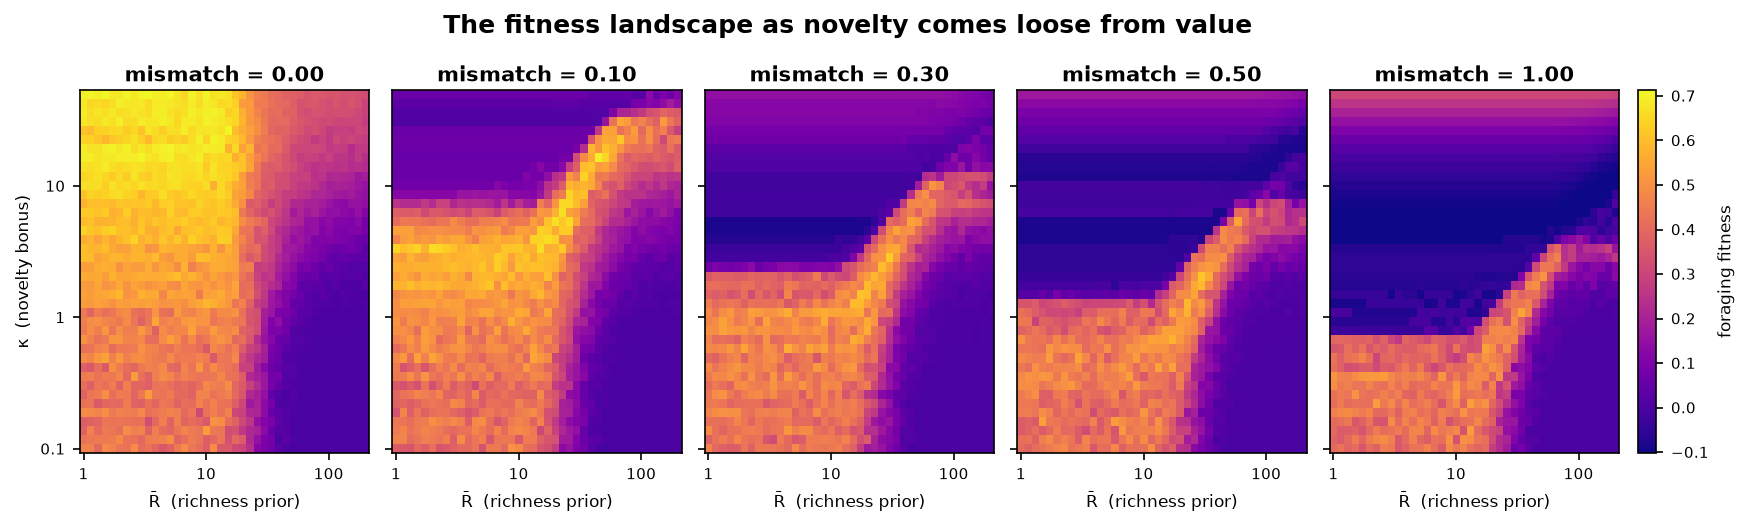

In [9]:
levels = [0, 0.1, 0.3, 0.5, 1]
even = False
render_landscapes.render(STACK, f'{OUT}/landscapes.png', levels, even)
display(Image(f'{OUT}/landscapes.png'))

Best forager at each mismatch level, on the whole grid and inside the box (R̄ ≤ 25,
κ ≤ 15) which I took to be biologically plausible. The standard error of a cell is
about 0.05.

In [5]:
summarise(STACK)

model=pure-v2  grid 40x40 (log)  box has 24x32 cells
standard error of a cell (between worlds): median 0.051, max 0.118
  mismatch=0.00  best +0.714 at R=1.5 k=50.00  | box best +0.687 at R=1.5 k=13.97
  mismatch=0.05  best +0.709 at R=22.8 k=11.92  | box best +0.709 at R=22.8 k=11.92
  mismatch=0.10  best +0.694 at R=44.9 k=16.39  | box best +0.667 at R=19.9 k=5.37
  mismatch=0.20  best +0.651 at R=34.2 k=4.58  | box best +0.637 at R=8.8 k=2.06
  mismatch=0.30  best +0.627 at R=29.9 k=2.84  | box best +0.608 at R=17.3 k=1.50
  mismatch=0.50  best +0.613 at R=29.9 k=2.06  | box best +0.585 at R=22.8 k=1.28
  mismatch=0.75  best +0.563 at R=15.1 k=0.49  | box best +0.563 at R=15.1 k=0.49
  mismatch=1.00  best +0.547 at R=34.2 k=1.09  | box best +0.536 at R=17.3 k=0.58
ancestral-tuned genome (top 10% of box at mismatch=0.10): ANCESTRAL_GENOME = (8.7, 2.98)


Score of the cell nearest to any R̄ and κ, at every mismatch level.

In [6]:
z = np.load(STACK)


def lookup(R_bar, kappa):
    i = np.abs(np.log(z['R_bar'] / R_bar)).argmin()
    j = np.abs(np.log(z['kappa'] / kappa)).argmin()
    print(f"nearest cell: R̄ = {z['R_bar'][i]:.1f}, κ = {z['kappa'][j]:.2f}")
    for m, f, se in zip(z['rungs'], z['F'][:, i, j], z['F_se'][:, i, j]):
        print(f'  m = {m:.2f}   {f:+.2f} ± {se:.2f}')


lookup(*ANCESTRAL_GENOME)

nearest cell: R̄ = 8.8, κ = 2.84
  m = 0.00   +0.60 ± 0.02
  m = 0.05   +0.57 ± 0.04
  m = 0.10   +0.54 ± 0.05
  m = 0.20   +0.42 ± 0.10
  m = 0.30   -0.02 ± 0.05
  m = 0.50   -0.06 ± 0.05
  m = 0.75   -0.06 ± 0.05
  m = 1.00   -0.05 ± 0.05


## Mismatch load

Red is the ancestral forager at every mismatch level, green is the best forager in the
box at that level. Both are rescored on 32 worlds the landscape didn't use.

red  : ['+0.556', '+0.267', '+0.078', '+0.027', '+0.025', '+0.023']
green: ['+0.564', '+0.471', '+0.562', '+0.500', '+0.470', '+0.501']
saved results/notebook/mismatch_load.png


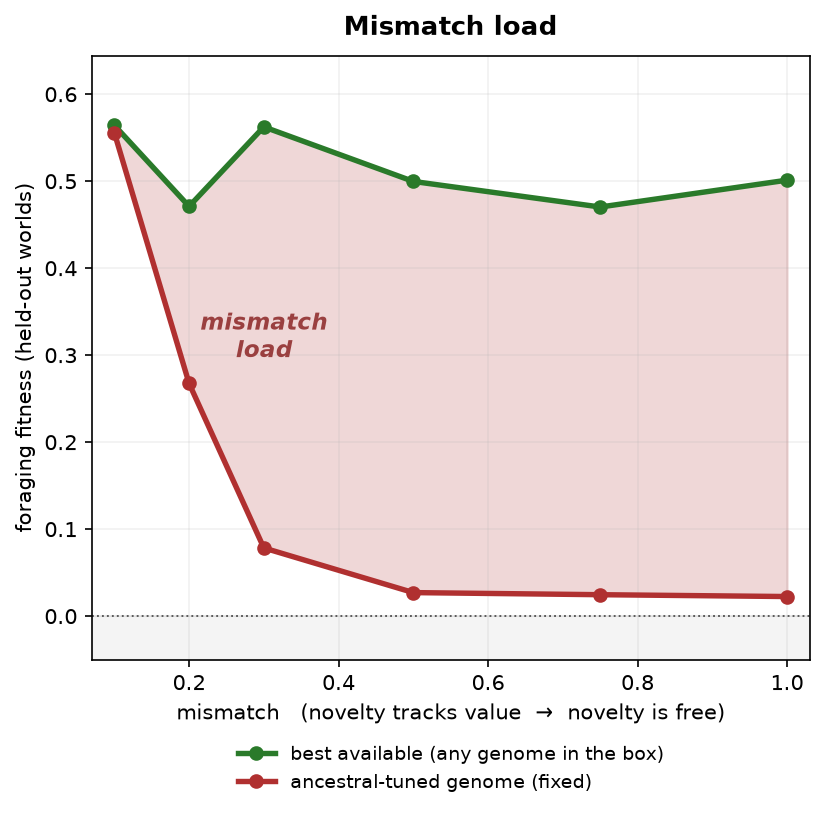

In [7]:
render_mismatch_load.render(f'{OUT}/mismatch_load.png')
display(Image(f'{OUT}/mismatch_load.png', width=450))

## Scoring a forager

Runs the fitness function on one world per mismatch level for 25,000 time units, same
as the landscape. Takes about a minute per level, and one world is noisy (the landscape
used 8).

In [8]:
genome = (8.7, 2.98)   # (R̄, κ), try (17.3, 0.58) which is the best in the box at m = 1

for m in (0.0, 0.3, 1.0):
    args = (np.array(genome), BASE_PARAMS, eval_seeds(1), 25_000, 20_000,
            {'mismatch_index': m, 'space_initial_patches': False})
    print(f'm = {m}:  fitness {evaluate_genome_per_world(args)[0]:+.2f}')

m = 0.0:  fitness +0.58
m = 0.3:  fitness -0.09
m = 1.0:  fitness -0.13
